# **Lab 7(A) - Laplacian Filter (Color Image)**

Name: Abdulrahman Saleh Alaamri
ID: 2240002427

I kept the moon image in color this time. filter2D and Laplacian work on each channel (R, G, B) separately, so the code is the same as the gray one except for loading and displaying. The moon.jpg file is a gray photo saved with 3 channels, so the result still looks gray.

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

## Apply Laplacian Filter on a Color Image to get a Sharp Image

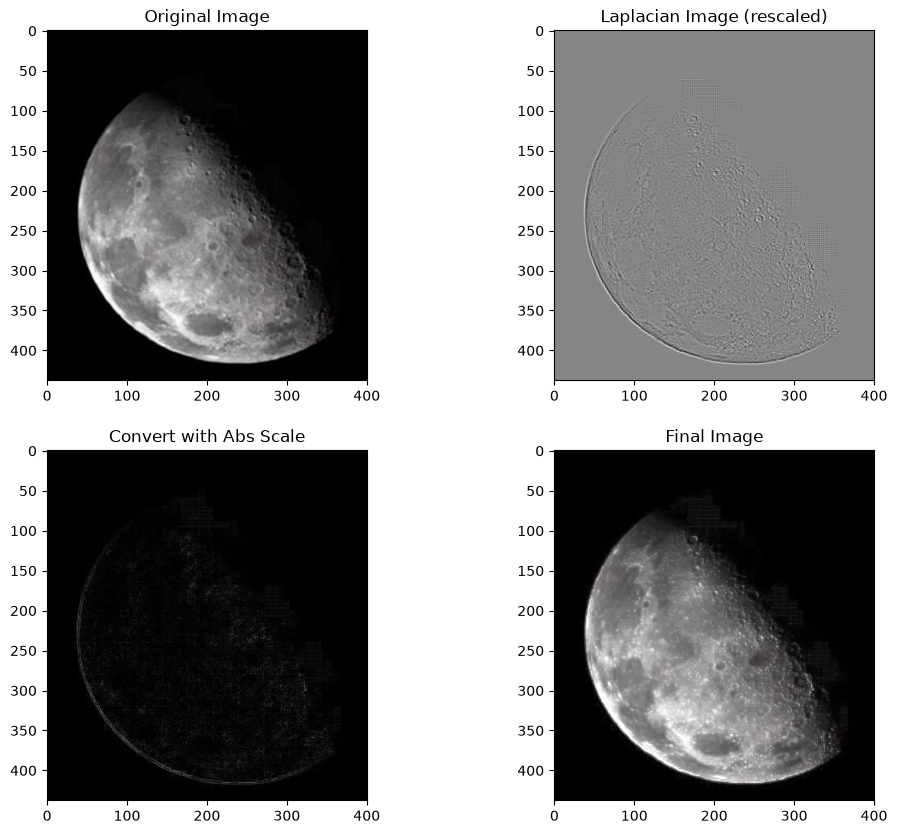

In [2]:
# ================ ( Laplacian Filter ) ===================

# 0. Image file path
imgFile = "moon.jpg"

# 1. Load image in color (flag 1) and convert BGR -> RGB for matplotlib
img = cv2.imread(imgFile, 1)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 2. Manually define the Laplacian Kernel
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Alternative kernel: Detects diagonal edges as well
# manual_kernel = np.array([
#     [1,  1,  1],
#     [1, -8,  1],
#     [1,  1,  1]
# ], dtype=np.float32)

# 3. Apply the filter using filter2D (it is applied to R, G and B separately)
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

# cv2.add stops at 255, while img + laplacian_abs wraps around on uint8
finalImage = cv2.add(img, laplacian_abs)

# the raw Laplacian has negative values so I rescale it to 0-1 only for display
laplacian_show = (laplacian_manual - laplacian_manual.min()) / (laplacian_manual.max() - laplacian_manual.min())

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_show), plt.title('Laplacian Image (rescaled)')
plt.subplot(223), plt.imshow(laplacian_abs), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage), plt.title('Final Image')
plt.show()

The Laplacian is computed for each channel, and adding it back to the original makes the craters and the edge of the moon sharper.

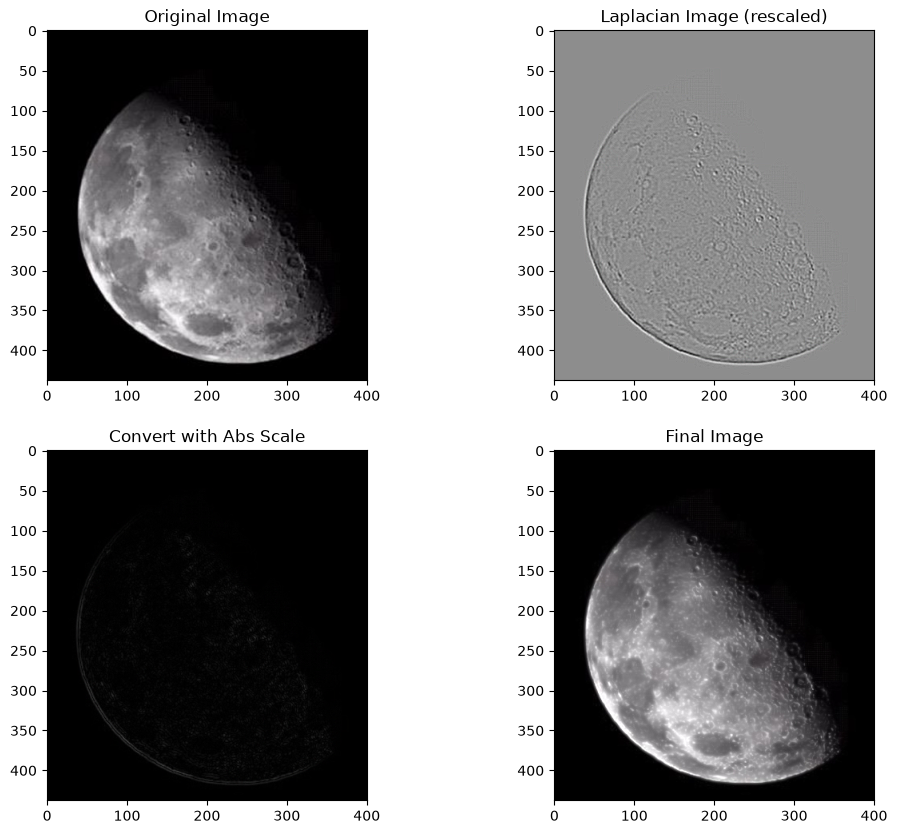

In [3]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm (per channel)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplace and original Image (saturating add)
finalImage2 = cv2.add(img, laplacian_8bit)

laplacian_show2 = (laplacian - laplacian.min()) / (laplacian.max() - laplacian.min())

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_show2), plt.title('Laplacian Image (rescaled)')
plt.subplot(223), plt.imshow(laplacian_8bit), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2), plt.title('Final Image')
plt.show()

Because the Gaussian blur is applied first, the tiny details are removed and this Laplacian has less noise than the first one.